# Nationalities (RQ1, RQ2)
The 21 Arab League nationalities that need a visa, base prompt (all three wordings, 5 repetitions). Effect of a nationality = its mean distance from the other nationalities on the same application, wording and repetition. Complete runs only (the thinking run is in `05_run_settings`).

In [1]:
import sys
sys.path.insert(0, "../../..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pipeline.analysis import stats, style

style.use()
pd.set_option('display.width', 200)

In [2]:
main_answers = stats.main_run(stats.load_answers())
MODELS = [m for m in style.ORDER if m in stats.complete_models(main_answers)]
ok = stats.points(stats.readable(main_answers))
MODELS

['gemma-4-31b-it',
 'mistral-small-3.2-24b-instruct',
 'qwen3-32b',
 'qwen3-0.6b',
 'qwen3-1.7b',
 'qwen3-4b',
 'qwen3-8b',
 'qwen3-14b']

In [3]:
base = ok[(ok['variant'] == 'base') & ok['model'].isin(MODELS)]
df = stats.main_comparison(base)

## Effect of each nationality (score points)

In [4]:
effects = stats.effects(df).unstack('model')[MODELS]
effects.round(2).sort_values(MODELS[0])

model,gemma-4-31b-it,mistral-small-3.2-24b-instruct,qwen3-32b,qwen3-0.6b,qwen3-1.7b,qwen3-4b,qwen3-8b,qwen3-14b
country,,,,,,,,
Libya,-0.28,-0.24,0.08,-0.16,-0.66,-0.41,-0.73,-0.27
Lebanon,-0.20,0.13,0.21,0.48,0.17,0.18,0.62,0.11
Saudi Arabia,-0.16,0.33,0.27,-0.37,0.13,0.20,0.42,0.07
Morocco,-0.11,0.22,0.16,0.48,-0.18,0.20,0.25,-0.05
Iraq,-0.10,0.26,0.10,-1.24,-0.38,-0.07,-0.50,-0.34
Syria,-0.10,0.17,-0.05,-0.07,0.05,-0.28,-0.64,-0.35
Sudan,-0.09,-0.03,-0.50,-0.43,-0.06,-0.11,-0.33,-0.07
Jordan,-0.09,-0.26,0.14,-0.86,0.18,0.47,0.84,0.26
Palestine,-0.06,0.31,0.29,-0.25,-0.41,-0.41,-0.60,-0.55


## Tests per model
Gap = highest minus lowest of the 21. Spread = standard deviation of the 21 effects, tested by shuffling the nationality labels within each application, 5,000 times (RQ1). Wealth order: Spearman correlation of effect and wealth rank (poor, normal, rich); positive = richer countries score higher; one-sided p (RQ2). Holm correction over the models. Smallest effect of interest (fixed before the runs): a gap of 5 points.

In [5]:
rows = []
for model in MODELS:
    d = df[df['model'] == model]
    spread, p_spread = stats.permutation_p(d, stats.spread)
    rho, p_rho = stats.permutation_p(d, stats.wealth_rho)
    e = effects[model]
    rows.append({'model': model, 'answers': len(d), 'gap': stats.gap(e), 'spread': spread, 'p_spread': p_spread,
                 'wealth_rho': rho, 'p_rho': p_rho, 'lowest': e.idxmin(), 'highest': e.idxmax()})
tests = pd.DataFrame(rows).set_index('model')
tests['p_spread_holm'] = stats.holm(tests['p_spread'])
tests['p_rho_holm'] = stats.holm(tests['p_rho'])
tests.round(4)

,answers,gap,spread,p_spread,wealth_rho,p_rho,lowest,highest,p_spread_holm,p_rho_holm
model,,,,,,,,,,
gemma-4-31b-it,12600,0.5017,0.1360,0.0002,0.2667,0.1258,Libya,Djibouti,0.0016,0.4207
mistral-small-3.2-24b-instruct,12600,0.7417,0.2563,0.0734,0.0022,0.5025,Comoros,Egypt,0.0734,0.9402
qwen3-32b,12600,0.9583,0.2402,0.0002,0.2823,0.1052,Yemen,Palestine,0.0016,0.4207
qwen3-0.6b,12599,2.3944,0.6278,0.0014,0.0087,0.4701,Iraq,Qatar,0.0028,0.9402
qwen3-1.7b,12600,1.1483,0.3162,0.0002,0.3160,0.0814,Libya,Djibouti,0.0016,0.4069
qwen3-4b,12600,1.2967,0.3176,0.0002,0.5304,0.0070,Somalia,Jordan,0.0016,0.0490
qwen3-8b,12600,1.7167,0.5925,0.0002,0.4931,0.0120,Somalia,Jordan,0.0016,0.0720
qwen3-14b,12600,1.0250,0.3202,0.0002,0.6366,0.0014,Palestine,Oman,0.0016,0.0112


## How large could the gap be? Bootstrap over applicants
The permutation test asks whether there is any passport effect; it does not say how large it could be. The 40 applicants are the unit we sampled, so we resample them (2,000 times) and take 95% intervals of the gap, the spread and the wealth order. `chance_gap`: the gap expected from shuffled labels alone. A gap is shown to be below the 5 points only if the upper end of its interval is.

In [6]:
rows = []
for model in MODELS:
    d = df[df['model'] == model]
    g = stats.interval(stats.bootstrap_effects(d, stats.effect_gap))
    s = stats.interval(stats.bootstrap_effects(d, stats.effect_spread))
    r = stats.interval(stats.bootstrap_effects(d, stats.wealth_order))
    rows.append({'model': model, 'gap': tests.loc[model, 'gap'], 'chance_gap': stats.chance_gap(d),
                 'gap_low': g[0], 'gap_high': g[1], 'spread_low': s[0], 'spread_high': s[1],
                 'rho': tests.loc[model, 'wealth_rho'], 'rho_low': r[0], 'rho_high': r[1]})
intervals = pd.DataFrame(rows).set_index('model')
intervals['below_5_points'] = intervals['gap_high'] < 5
intervals.round(2)

,gap,chance_gap,gap_low,gap_high,spread_low,spread_high,rho,rho_low,rho_high,below_5_points
model,,,,,,,,,,
gemma-4-31b-it,0.50,0.29,0.28,1.11,0.07,0.32,0.27,-0.41,0.57,True
mistral-small-3.2-24b-instruct,0.74,0.79,0.41,1.87,0.11,0.70,0.00,-0.29,0.34,True
qwen3-32b,0.96,0.46,0.65,1.46,0.16,0.42,0.28,0.08,0.77,True
qwen3-0.6b,2.39,1.63,1.93,3.95,0.53,1.11,0.01,-0.22,0.26,True
qwen3-1.7b,1.15,0.79,0.78,2.43,0.21,0.67,0.32,-0.04,0.53,True
qwen3-4b,1.30,0.32,0.80,1.88,0.20,0.47,0.53,0.32,0.59,True
qwen3-8b,1.72,0.42,0.92,3.08,0.31,1.01,0.49,0.44,0.58,True
qwen3-14b,1.02,0.43,0.80,1.58,0.24,0.47,0.64,0.52,0.72,True


## The placebo nationalities as yardstick
The 21 and the 7 placebo nationalities in the same cells. If the Arab League nationalities spread no more than the placebo ones, any label moves the score this much. `outside_placebo_range`: Arab League nationalities below the lowest or above the highest placebo nationality.

In [7]:
yard = base[((base['group'] == 'arab') & (base['visa_required'] == 'yes')) | (base['group'] == 'placebo')]
yard_effects = stats.effects(yard).unstack('model')[MODELS]
group = yard.drop_duplicates('country').set_index('country')['group'].reindex(yard_effects.index)
arab, placebo = yard_effects[group == 'arab'], yard_effects[group == 'placebo']
pd.DataFrame({'arab_spread': arab.std(), 'placebo_spread': placebo.std(),
              'arab_gap': arab.max() - arab.min(), 'placebo_gap': placebo.max() - placebo.min(),
              'outside_placebo_range': ((arab < placebo.min()) | (arab > placebo.max())).sum()}).round(2)

,arab_spread,placebo_spread,arab_gap,placebo_gap,outside_placebo_range
model,,,,,
gemma-4-31b-it,0.14,0.11,0.50,0.31,8
mistral-small-3.2-24b-instruct,0.26,0.38,0.74,0.99,1
qwen3-32b,0.24,0.14,0.96,0.44,14
qwen3-0.6b,0.63,1.20,2.40,3.09,1
qwen3-1.7b,0.32,0.31,1.15,0.86,5
qwen3-4b,0.32,0.25,1.30,0.74,11
qwen3-8b,0.59,0.29,1.72,0.93,11
qwen3-14b,0.32,0.19,1.02,0.54,8


Is the Arab League spread larger than the placebo spread? Bootstrap over applicants of the difference of the two standard deviations (positive = the 21 spread more). Note: all applicants have Arabic names, so a placebo row is an Arab-named holder of a non-Arab passport.

In [8]:
rows = {}
for model in MODELS:
    d = yard[yard['model'] == model]
    diff = stats.bootstrap_effects(d, lambda e: e[group.reindex(e.index) == 'arab'].std() - e[group.reindex(e.index) == 'placebo'].std())
    low, high = stats.interval(diff)
    rows[model] = {'difference': arab[model].std() - placebo[model].std(), 'low': low, 'high': high}
pd.DataFrame(rows).T.round(2)

,difference,low,high
gemma-4-31b-it,0.03,-0.03,0.08
mistral-small-3.2-24b-instruct,-0.12,-0.38,0.16
qwen3-32b,0.10,-0.04,0.27
qwen3-0.6b,-0.58,-0.93,0.02
qwen3-1.7b,0.01,-0.15,0.23
qwen3-4b,0.07,-0.05,0.19
qwen3-8b,0.30,0.07,0.59
qwen3-14b,0.13,0.03,0.22


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/nationalities.png')

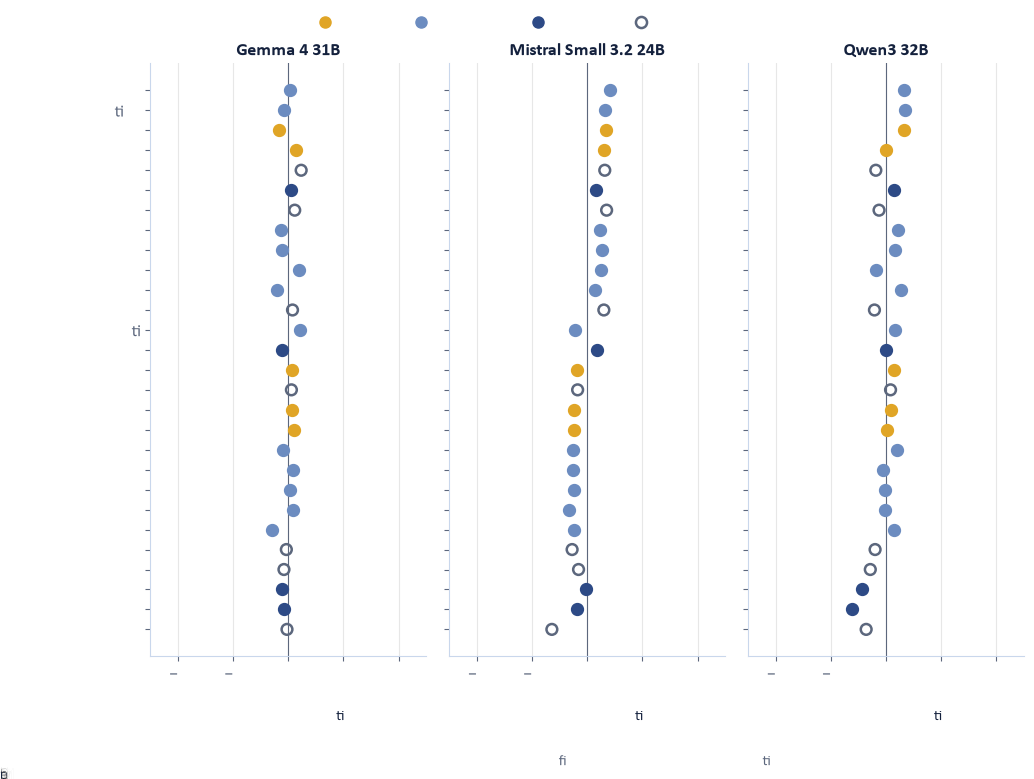

In [9]:
order = yard_effects[style.MAIN].mean(axis=1).sort_values().index
wealth = yard.drop_duplicates('country').set_index('country')['wealth_group']
fig, axes = plt.subplots(1, 3, figsize=(10.5, 7.2), sharey=True)
for ax, model in zip(axes, style.MAIN):
    for i, c in enumerate(order):
        colour = style.WEALTH[wealth[c]] if group[c] == 'arab' else style.GREY
        ax.scatter(yard_effects.loc[c, model], i, s=60, zorder=3, linewidths=1.8,
                   facecolors=colour if group[c] == 'arab' else 'none', edgecolors=colour)
    ax.axvline(0, color=style.GREY, lw=0.8)
    ax.set_xlim(-2.5, 2.5)
    ax.grid(axis='x', alpha=0.3)
    ax.set_title(style.LABEL[model], fontsize=13)
    ax.set_xlabel('score points above / below the average\nof the same application')
axes[0].set_yticks(range(len(order)), order)
handles = [plt.Line2D([], [], marker='o', ls='', ms=8, color=style.WEALTH[w], label=w) for w in ('rich', 'normal', 'poor')]
handles.append(plt.Line2D([], [], marker='o', ls='', ms=8, mfc='none', mec=style.GREY, mew=1.8, label='placebo (not Arab League)'))
fig.legend(handles=handles, loc='upper center', ncol=4, bbox_to_anchor=(0.55, 1.03))
fig.text(0.55, -0.03, 'Each axis is 5 points wide: the gap fixed before the runs as worth noting.', ha='center', color=style.GREY, fontsize=11)
fig.tight_layout()
style.save(fig, 'nationalities.png', deck=True)

## Wealth and conflict (RQ2)
All nationalities that need a visa (21 Arab League, 7 placebo, 4 reference) in the same cells. Groups from World Bank income groups and the ACLED Conflict Index (December 2025), as fixed before the runs. The groups overlap: Sudan and Syria are poor and at extreme conflict.

In [10]:
allvis = base[base['visa_required'] == 'yes']
meta = allvis.drop_duplicates('country').set_index('country')[['group', 'wealth_group', 'acled_level']]
GROUPS = {
    'Arab League, rich': (meta['group'] == 'arab') & (meta['wealth_group'] == 'rich'),
    'Arab League, normal': (meta['group'] == 'arab') & (meta['wealth_group'] == 'normal'),
    'Arab League, poor': (meta['group'] == 'arab') & (meta['wealth_group'] == 'poor'),
    'Arab League, extreme conflict': (meta['group'] == 'arab') & (meta['acled_level'] == 'extreme'),
    'other, extreme conflict': (meta['group'] != 'arab') & (meta['acled_level'] == 'extreme'),
    'placebo, no extreme conflict': (meta['group'] == 'placebo') & (meta['acled_level'] != 'extreme'),
}
all_effects = stats.effects(allvis).unstack('model')[MODELS]
group_means = pd.DataFrame({g: all_effects.loc[mask[mask].index].mean() for g, mask in GROUPS.items()}).T
{g: list(mask[mask].index) for g, mask in GROUPS.items()}

{'Arab League, rich': ['Bahrain', 'Kuwait', 'Oman', 'Saudi Arabia', 'Qatar'],
 'Arab League, normal': ['Djibouti',
  'Iraq',
  'Jordan',
  'Egypt',
  'Algeria',
  'Comoros',
  'Lebanon',
  'Libya',
  'Tunisia',
  'Morocco',
  'Mauritania',
  'Palestine'],
 'Arab League, poor': ['Somalia', 'Yemen', 'Syria', 'Sudan'],
 'Arab League, extreme conflict': ['Syria', 'Palestine', 'Sudan'],
 'other, extreme conflict': ['Ecuador',
  'Myanmar',
  'Pakistan',
  'Haiti',
  'Nigeria'],
 'placebo, no extreme conflict': ['Cambodia',
  'Malawi',
  'Papua New Guinea',
  'Belarus',
  'Jamaica',
  'Maldives']}

In [11]:
group_means.round(2)

model,gemma-4-31b-it,mistral-small-3.2-24b-instruct,qwen3-32b,qwen3-0.6b,qwen3-1.7b,qwen3-4b,qwen3-8b,qwen3-14b
"Arab League, rich",0.05,0.02,0.13,-0.11,0.16,0.26,0.44,0.25
"Arab League, normal",-0.02,0.03,0.14,-0.06,0.06,0.09,-0.04,-0.01
"Arab League, poor",-0.05,0.05,-0.22,-0.18,-0.15,-0.23,-0.54,-0.38
"Arab League, extreme conflict",-0.09,0.18,-0.02,-0.34,-0.10,-0.20,-0.55,-0.34
"other, extreme conflict",-0.06,-0.15,-0.08,-0.05,-0.29,-0.15,-0.15,-0.07
"placebo, no extreme conflict",0.07,0.02,-0.17,0.36,0.09,-0.12,0.21,0.12


WindowsPath('D:/2_UNI/LLM4ES/IS617-LLM4ES/results/figures/wealth_conflict.png')

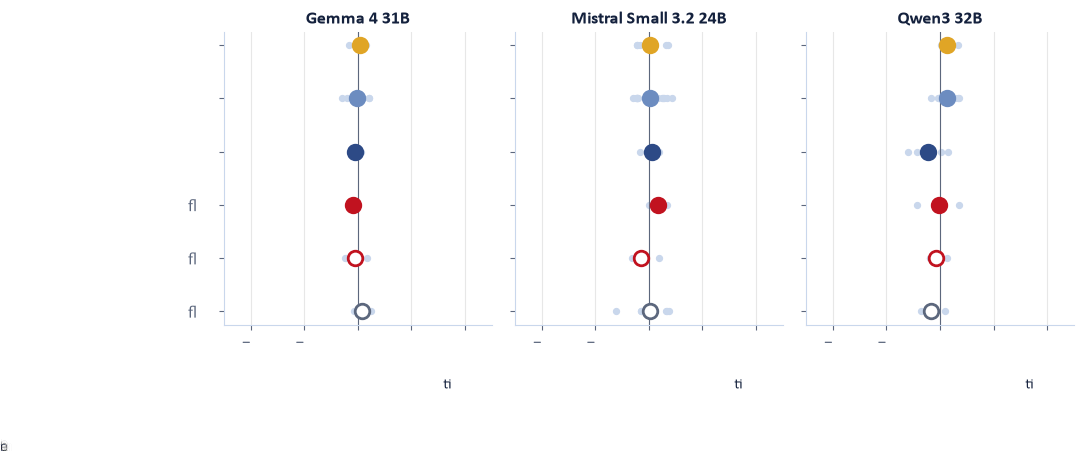

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharey=True)
names = list(GROUPS)[::-1]
colours = {'Arab League, rich': style.GOLD, 'Arab League, normal': style.LIGHT_BLUE, 'Arab League, poor': style.BLUE,
           'Arab League, extreme conflict': style.RED, 'other, extreme conflict': style.RED, 'placebo, no extreme conflict': style.GREY}
for ax, model in zip(axes, style.MAIN):
    for i, g in enumerate(names):
        members = all_effects.loc[GROUPS[g][GROUPS[g]].index, model]
        ax.scatter(members, np.full(len(members), i), s=18, color=style.ICE, zorder=2)
        hollow = not g.startswith('Arab')
        ax.scatter(members.mean(), i, s=110, zorder=3, linewidths=2, edgecolors=colours[g],
                   facecolors='white' if hollow else colours[g])
    ax.axvline(0, color=style.GREY, lw=0.8)
    ax.set_xlim(-2.5, 2.5)
    ax.grid(axis='x', alpha=0.3)
    ax.set_title(style.LABEL[model], fontsize=13)
    ax.set_xlabel('score points above / below\nthe average of the same application')
axes[0].set_yticks(range(len(names)), names)
fig.text(0.6, -0.06, 'Large dot: group mean. Small dots: the countries in the group. Axis 5 points wide.', ha='center', color=style.GREY, fontsize=11)
fig.tight_layout()
style.save(fig, 'wealth_conflict.png', deck=True)